In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/puttadatta/social-media-ads/social_ads.csv


In [2]:
ads = pd.read_csv('/kaggle/input/datasets/puttadatta/social-media-ads/social_ads.csv')
ads.head()

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0


In [3]:
ads.shape

(400, 3)

In [4]:
ads.isnull().sum()

Age                0
EstimatedSalary    0
Purchased          0
dtype: int64

In [5]:
ads['Purchased'].value_counts()

Purchased
0    257
1    143
Name: count, dtype: int64

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

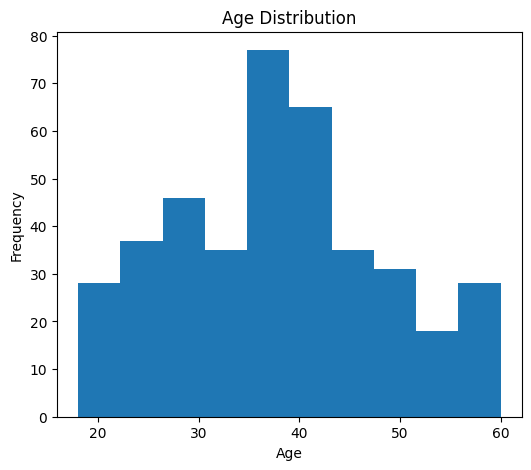

In [7]:

plt.figure(figsize = (6,5))
plt.hist(ads['Age'],bins = 10)
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

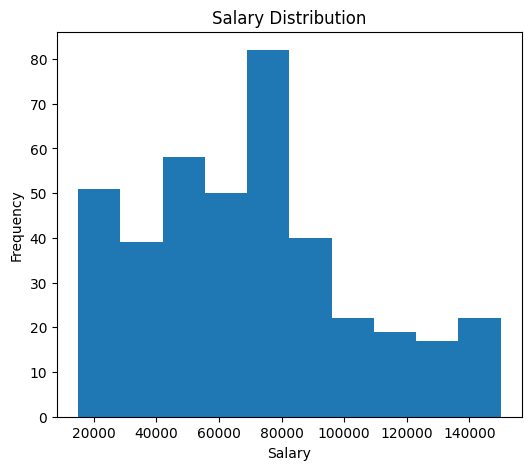

In [8]:
plt.figure(figsize = (6,5))
plt.hist(ads['EstimatedSalary'],bins = 10)
plt.title('Salary Distribution')
plt.xlabel('Salary')
plt.ylabel('Frequency')
plt.show()

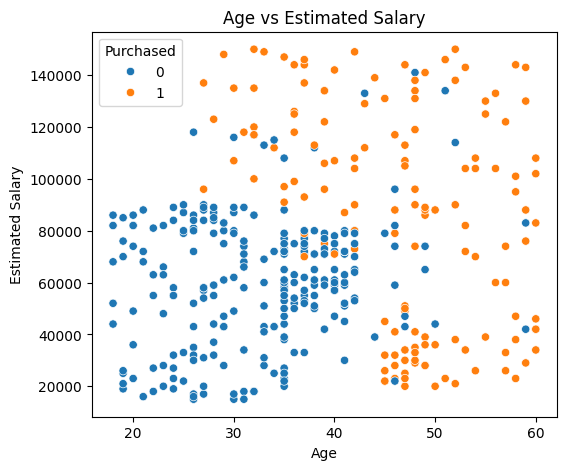

In [9]:
plt.figure(figsize = (6,5))

sns.scatterplot(
    data = ads,
    x = 'Age',
    y = 'EstimatedSalary',
    hue = 'Purchased'
)

plt.title('Age vs Estimated Salary')
plt.xlabel('Age')
plt.ylabel('Estimated Salary')
plt.show()

In [10]:
from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [11]:
x = ads[['Age', 'EstimatedSalary']]
y = ads['Purchased']

x_train,x_test,y_train,y_test = train_test_split(
    x,y,test_size = 0.2, random_state = 42
)

model = DecisionTreeClassifier()
model.fit(x_train,y_train)

DecisionTreeClassifier()

In [12]:
y_pred = model.predict(x_test)

In [13]:
accuracy = accuracy_score(y_test,y_pred)
print(accuracy)

0.8375


In [14]:
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[46  6]
 [ 7 21]]
              precision    recall  f1-score   support

           0       0.87      0.88      0.88        52
           1       0.78      0.75      0.76        28

    accuracy                           0.84        80
   macro avg       0.82      0.82      0.82        80
weighted avg       0.84      0.84      0.84        80



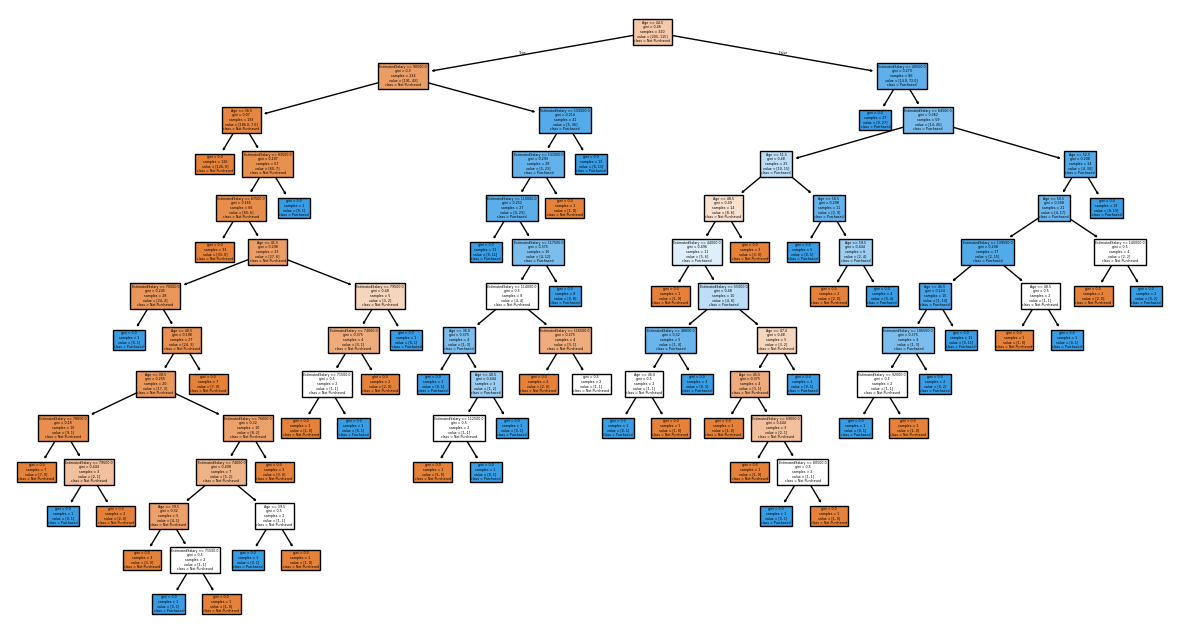

In [15]:
plt.figure(figsize=(15,8))
tree.plot_tree(
    model,
    filled=True,
    feature_names=['Age', 'EstimatedSalary'],
    class_names=['Not Purchased', 'Purchased']
)
plt.show()

In [16]:
model.feature_importances_

array([0.47260505, 0.52739495])

In [17]:
results = []

for depth in [2,4,6,8]:
    model = DecisionTreeClassifier(
        max_depth = depth,
        random_state = 42
    )

    model.fit(x_train,y_train)
    train_acc = model.score(x_train,y_train)
    test_acc = model.score(x_test,y_test)
    results.append([depth,train_acc,test_acc])

pd.DataFrame(
    results,
    columns = ['Depth','Train Accuracy','Test Accuracy']
)


,Depth,Train Accuracy,Test Accuracy
0,2,0.91875,0.9125
1,4,0.93125,0.9125
2,6,0.95000,0.8625
3,8,0.97500,0.8500


In [18]:
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [2, 4, 6, 8, 10],
    'min_samples_split': [2, 5, 10]
}

model = DecisionTreeClassifier(random_state=42)

grid = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid.fit(x_train, y_train)

print("Best Params:", grid.best_params_)
print("Best CV Accuracy:", grid.best_score_)

best_model = grid.best_estimator_

y_pred = best_model.predict(x_test)

accuracy = accuracy_score(y_test, y_pred)

print("Test Accuracy:", accuracy)
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

Best Params: {'criterion': 'entropy', 'max_depth': 8, 'min_samples_split': 5}
Best CV Accuracy: 0.90625
Test Accuracy: 0.8375
[[46  6]
 [ 7 21]]
              precision    recall  f1-score   support

           0       0.87      0.88      0.88        52
           1       0.78      0.75      0.76        28

    accuracy                           0.84        80
   macro avg       0.82      0.82      0.82        80
weighted avg       0.84      0.84      0.84        80



In [19]:
from sklearn.ensemble import RandomForestClassifier

In [20]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

model2 = RandomForestClassifier(
    random_state=42
)

model2.fit(x_train, y_train)

yrf_pred = model2.predict(x_test)

rf_accuracy = accuracy_score(y_test, yrf_pred)

print("Accuracy:", rf_accuracy)
print(confusion_matrix(y_test, yrf_pred))
print(classification_report(y_test, yrf_pred))

Accuracy: 0.9
[[46  6]
 [ 2 26]]
              precision    recall  f1-score   support

           0       0.96      0.88      0.92        52
           1       0.81      0.93      0.87        28

    accuracy                           0.90        80
   macro avg       0.89      0.91      0.89        80
weighted avg       0.91      0.90      0.90        80



In [21]:
comparison1 = pd.DataFrame({
    'Model':['Decision Tree', 'Random Forest'],
    'Accuracy':[accuracy,rf_accuracy]
})
comparison1

,Model,Accuracy
0,Decision Tree,0.8375
1,Random Forest,0.9000


In [22]:
df_train_acc = accuracy_score(
    y_train,
    best_model.predict(x_train)
)

df_test_acc = accuracy_score(
    y_test,
    best_model.predict(x_test)
)

rf_train_acc = accuracy_score(
    y_train,
    model2.predict(x_train)
)

rf_test_acc = accuracy_score(
    y_test,
    model2.predict(x_test)
)

comparision = pd.DataFrame({
    'Model':['Decision Tree', 'Random Forest'],
    'Train Acc':[df_train_acc,rf_train_acc],
    'Test Acc':[df_test_acc,rf_test_acc]
})

comparision

,Model,Train Acc,Test Acc
0,Decision Tree,0.962500,0.8375
1,Random Forest,0.996875,0.9000


In [23]:
model2.feature_importances_

array([0.48309389, 0.51690611])

In [24]:
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [2, 3, 4, 5, 6, None],
    'min_samples_split': [2, 5, 10],
    'max_features': ['sqrt', 'log2']
}

rf_model = RandomForestClassifier(
    random_state=42,
    oob_score=True
)

grid_rf = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid_rf,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_rf.fit(x_train, y_train)

GridSearchCV(cv=5,
             estimator=RandomForestClassifier(oob_score=True, random_state=42),
             n_jobs=-1,
             param_grid={'max_depth': [2, 3, 4, 5, 6, None],
                         'max_features': ['sqrt', 'log2'],
                         'min_samples_split': [2, 5, 10],
                         'n_estimators': [50, 100, 200]},
             scoring='accuracy')